In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.colorbar import Colorbar
from matplotlib import colors
from matplotlib.legend_handler import HandlerTuple
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from scipy import special
from scipy.stats import linregress
from scipy.optimize import curve_fit
from mycolorpy import colorlist as mcp
from pathlib import Path
import pandas as pd
import matplotlib as mpl
import glob 
import os
import h5py


plt.rcParams["text.usetex"] = True
plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}\usepackage{xcolor}"
plt.rcParams["font.family"] = "lmodern"

In [4]:
cwd = Path().resolve()
project_root = cwd.parent

data_equilibrium_dir = project_root / "data" / "equilibrium"
data_quench_dir = project_root / "data" / "quench" / "quench_paper"
data_quench_NNN_dir = project_root / "data" / "quench" / "quench_paper" / "NNN"
plot_dir = project_root / "plot"/"figures"/"figures_paper"
checkpoint_dir = project_root / "checkpoints" / "quench" / "quench_paper"

In [5]:
APS_RC = {
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    # ticks on all four sides, pointing inward, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    # embed TrueType fonts (Type 42) instead of Type 3
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

In [6]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)

In [36]:
def set_zero_at(ax, dmin, dmax, frac, pad=1.08):
    """Set y-limits so that y = 0 sits at fraction `frac` of the axis height
    (0 = bottom, 0.5 = middle) and all the data fit."""
    L = 0.0
    if dmax > 0:
        L = max(L, dmax / (1 - frac))
    if dmin < 0 and frac > 0:
        L = max(L, -dmin / frac)
    L *= pad
    ax.set_ylim(-frac * L, (1 - frac) * L)


def figure_1_paper():

    with plt.rc_context(APS_RC):

        # ------------------------------------------------------------ data
        df1 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V1.0_entr_evrey_1_entanglement.csv")
        df2 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V0.5_entr_evrey_1_entanglement.csv")
        df3 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V1.0_fluctuations.csv")
        df4 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V0.5_fluctuations.csv")

        times1, Entropy1 = df1["Time"].values, df1["Entropy"].values
        times2, Entropy2 = df2["Time"].values, df2["Entropy"].values
        times3, Fluctuations3 = df3["Time"].values, df3["Variance"].values
        times4, Fluctuations4 = df4["Time"].values, df4["Variance"].values

        # Delta X(t) = X(t) - X(0), in units of 10^-3 (the factor is written at the top of the axes)
        scale = 1e3
        dS1 = (Entropy1 - Entropy1[0]) * scale
        dS2 = (Entropy2 - Entropy2[0]) * scale
        dF3 = (Fluctuations3 - Fluctuations3[0]) * scale
        dF4 = (Fluctuations4 - Fluctuations4[0]) * scale

        # ------------------------------------------------------------ figure
        fig, ax1 = plt.subplots(figsize=(3.4, 2.7))
        ax2 = ax1.twinx()

        lw = 1.2
        color_S = 'tab:blue'
        color_F = 'dimgray'

        # solid = first quench, dashed = second quench
        l1, = ax1.plot(times1, dS1, color=color_S, linestyle='-', linewidth=lw)
        l2, = ax1.plot(times2, dS2, color=color_S, linestyle='--', linewidth=lw)
        l3, = ax2.plot(times3, dF3, color=color_F, linestyle='-', linewidth=lw)
        l4, = ax2.plot(times4, dF4, color=color_F, linestyle='--', linewidth=lw)

        # thin line marking Delta F = 0 on the right axis
        ax2.axhline(0, color=color_F, linewidth=0.6, alpha=0.6)

        # ------------------------------------------------------------ y-limits
        # fraction of the axis height at which y = 0 sits:
        #   zero_frac_S = 0.0 -> entropy starts from the bottom, fluctuations from the middle
        #                        (offset layout: the four curves do not start on top of each other)
        #   zero_frac_S = zero_frac_F -> the two zeros coincide
        zero_frac_S = 0.0
        zero_frac_F = 0.5
        set_zero_at(ax1, min(dS1.min(), dS2.min()), max(dS1.max(), dS2.max()), zero_frac_S)
        set_zero_at(ax2, min(dF3.min(), dF4.min()), max(dF3.max(), dF4.max()), zero_frac_F)
        ax1.set_xlim(0, times1.max())

        # ------------------------------------------------------------ axes styling
        ax1.set_xlabel(r"Time $t$")
        ax1.set_ylabel(r"$\Delta S_A(t)$", color=color_S)
        ax2.set_ylabel(r"$\Delta\mathcal{F}_A(t)$", color=color_F, labelpad = 0)

        # only the numbers are colored; ticks and spines stay black
        ax1.tick_params(axis='y', which='both', labelcolor=color_S,
                        direction='in', left=True, right=False)
        ax2.tick_params(axis='y', which='both', labelcolor=color_F,
                        direction='in', left=False, right=True)
        ax1.tick_params(axis='x', which='both', direction='in', top=True)

        ax1.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax2.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))

        # scale factors at the top of each axis, not in the labels
        ax1.text(0.0, 1.01, r"$\times 10^{-3}$", transform=ax1.transAxes,
                 ha='left', va='bottom', fontsize=10, color=color_S)
        ax2.text(1.0, 1.01, r"$\times 10^{-3}$", transform=ax2.transAxes,
                 ha='right', va='bottom', fontsize=10, color=color_F)

        # ------------------------------------------------------------ legend
        # attached to ax2 (top-most axes) so that no curve is drawn over it
        ax2.legend(
            [(l1, l3), (l2, l4)],
            [r"$V/t_0:\ 0.5 \to 0.25$",
             r"$V/t_0:\ 0.25 \to 0.5$"],
            loc='upper left', frameon=True, edgecolor='lightgray',
            handler_map={tuple: HandlerTuple(ndivide=None)},
            handlelength=2.4, borderpad=0.4, labelspacing=0.3, fontsize=6.2
        )

        fig.tight_layout(pad=0.3)
        fig.savefig(plot_dir / "figure_1.pdf", bbox_inches='tight', pad_inches=0.03)
        fig.savefig(plot_dir / "figure_1.png", dpi=300)
        plt.show()

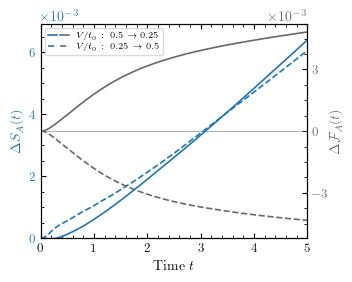

In [37]:
figure_1_paper()

In [26]:
def figure_2_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig_h = 4.2
        fig = plt.figure(figsize=(3.4, fig_h))
        spec = gridspec.GridSpec(nrows=3, ncols=1, hspace=0, left=0.18, right=0.97, top=0.985, bottom=0.55 / fig_h)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)
        ax3 = fig.add_subplot(spec[2, 0], sharex=ax1)

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.25_t20.0_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / ( np.pi**2) 

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        # --- perform fit ---
        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        Fluctuations_fit_a = Fluctuations_a[mask_a]
        x_data_a = np.log(times_fit_a)
        y_data_a = Fluctuations_fit_a
        slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        # fit_curve = slope * np.log(t_line) + intercept
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.semilogx(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, markevery = m_spacing,
                            markeredgewidth=m_ew, label=r"Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a*100, color='black', linestyle='--', 
                            linewidth=1.2, label=theory_label)

        ax1.legend(handles=[l_a_1, l_a_2], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.24, 0.32, r"$n=1/4$", transform=ax1.transAxes, ha='right', va ='bottom')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.3333333333333333_t20.0_Vi0.7_Vf0.5.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 400/1200
        t_2_b = 0
        V_i_b = 0.7
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / ( np.pi**2) 

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        # --- perform fit ---
        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        Fluctuations_fit_b = Fluctuations_b[mask_b]
        x_data_b = np.log(times_fit_b)
        y_data_b = Fluctuations_fit_b
        slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.semilogx(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)
        l_b_2, = ax2.semilogx(t_line_b, theory_curve_b*100, color='black', linestyle='--', 
                            linewidth=1.2)

        ax2.text(0.24, 0.5, r"$n=1/3$", transform=ax2.transAxes, ha='right', va ='bottom')
        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        # ------------------------------------------------------ ax3 


        df_c = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5.csv")

        times_c = df_c["Time"].values
        Fluctuations_c = df_c["Variance"].values

        # --- Param Bethe Ansatz---
        V_i_c = 0.7
        V_f_c = 0.5
        mu_i = np.arccos(V_i_c / 2)
        mu_f = np.arccos(V_f_c / 2)

        K_i_c = np.pi / (2 * (np.pi - mu_i))
        K_f_c = np.pi / (2 * (np.pi - mu_f))

        B_param_c = 0.5 * (K_i_c**2 - K_f_c**2) / (K_i_c * K_f_c)
        m_theory_c = - B_param_c * K_f_c / ( np.pi**2) 

        Fluctuations_c = Fluctuations_c - Fluctuations_c[0]  
        Fluctuations_c = Fluctuations_c[1:]
        times_c = times_c[1:]

        # --- perform fit ---
        mask_c = (times_c >= 2.0) & (times_c <= 3.0)
        times_fit_c = times_c[mask_c]
        Fluctuations_fit_c = Fluctuations_c[mask_c]
        x_data_c = np.log(times_fit_c)
        y_data_c = Fluctuations_fit_c
        slope, intercept_c, r_value, p_value, std_err = linregress(x_data_c, y_data_c)
        intercept_c = np.mean(y_data_c - m_theory_c * np.log(times_fit_c))


        t_line_c = np.linspace(0.5, 7, 200)
        theory_curve_c = m_theory_c * np.log(t_line_c) + intercept_c 

        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_c_1, = ax3.semilogx(times_c, Fluctuations_c * 100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, 
                            markeredgewidth=m_ew)
        l_c_2, = ax3.semilogx(t_line_c, theory_curve_c *100, color='black', linestyle='--', 
                            linewidth=1.2)
        ax3.text(0.24, 0.5, r"$n=1/2$", transform=ax3.transAxes, ha='right', va ='bottom')
        ax3.text(0.96, 0.10, r"(c)", transform=ax3.transAxes, ha='right', va ='bottom', weight= 'bold')

        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax3.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}_A(t)$", x=0.03, y=0.56, fontsize=10)
        ax1.text(0.0, 1.01, r"$\times 10^{-2}$", transform=ax1.transAxes,
                         ha='left', va='bottom', fontsize=10)

        for ax in (ax1, ax2, ax3):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax2, ax3):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)
        ax1.legend(fontsize = 10)
        plt.savefig(plot_dir / "figure_2.pdf", bbox_inches='tight', pad_inches=0.03)

        plt.show()

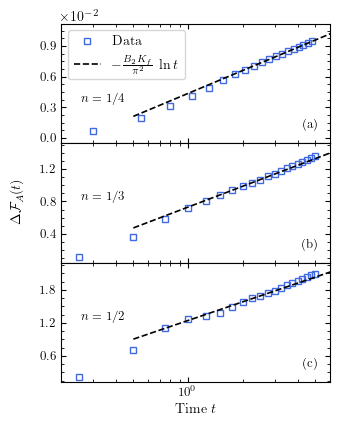

In [29]:
figure_2_paper()

In [30]:
def figure_3_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig = plt.figure(figsize=(3.4, 3.6))
        spec = gridspec.GridSpec(nrows=2, ncols=1, hspace=0, left=0.18, right=0.97, top=0.98, bottom=0.12)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1200_FillingFraction0.25_t20.1_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0.1
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / ( np.pi**2) 

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        # --- perform fit ---
        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        Fluctuations_fit_a = Fluctuations_a[mask_a]
        x_data_a = np.log(times_fit_a)
        y_data_a = Fluctuations_fit_a
        slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        # fit_curve = slope * np.log(t_line) + intercept
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.semilogx(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, markevery = m_spacing,
                            markeredgewidth=m_ew, label=r"Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a*100, color='black', linestyle='--', 
                            linewidth=1.2, label=theory_label)

        ax1.legend(handles=[l_a_1, l_a_2], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_to_NNN_ctr-N1200_FillingFraction0.25_t2i0.0_t2f0.2.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 0.25
        t_2_i_b = 0.0
        t_2_f_b = 0.2
        V_i_b = 0.5
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_i_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_f_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / ( np.pi**2) 

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        # --- perform fit ---
        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        Fluctuations_fit_b = Fluctuations_b[mask_b]
        x_data_b = np.log(times_fit_b)
        y_data_b = Fluctuations_fit_b
        slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.semilogx(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)
        l_b_2, = ax2.semilogx(t_line_b, theory_curve_b*100, color='black', linestyle='--', 
                            linewidth=1.2)

        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax2.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}_A(t)$", x=0.03, y=0.55, fontsize=10)
        ax1.text(0.0, 1.01, r"$\times 10^{-2}$", transform=ax1.transAxes,
                    ha='left', va='bottom', fontsize=10)
        ax1.tick_params(axis='x', labelbottom=False)
        for ax in (ax1, ax2):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax1, ax2):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)

        ax1.text(0.96, 0.30, r"$V/t_0:\ 0.7 \to 0.5$", transform=ax1.transAxes,
         ha='right', va='bottom', weight='bold')
        ax2.text(0.96, 0.30, r"$t_2/t_0:\ 0.0 \to 0.2$", transform=ax2.transAxes,
         ha='right', va='bottom', weight='bold')

        plt.savefig(plot_dir / "figure_3.pdf", bbox_inches='tight', pad_inches=0.03)

        plt.show()

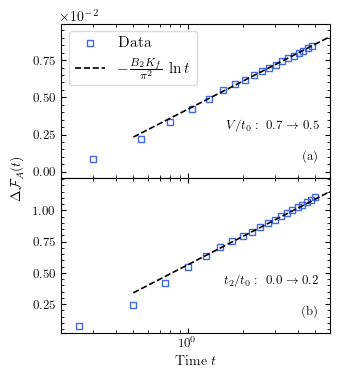

In [31]:
figure_3_paper()

In [32]:
def figure_SSH_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig = plt.figure(figsize=(3.4, 3.6))
        spec = gridspec.GridSpec(nrows=2, ncols=1, hspace=0, left=0.18, right=0.97, top=0.98, bottom=0.12)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)

        m_size = 4.5
        m_ew = 1.0

        # ----------------------------------------------- ax1 
        df_a = pd.read_csv(data_quench_dir / "NNN/quench_SSH_ctr-N1200_FillingFraction0.25_wi0.2_wf0.3.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]

        l_a_1, = ax1.plot(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew, label=r"Data")

        ax1.legend(handles=[l_a_1], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_SSH_ctr-N1200_FillingFraction0.25_Vi0.7_Vf0.5.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]


        l_b_1, = ax2.plot(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)

        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax2.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}_A(t)$", x=0.03, y=0.55, fontsize=10)
        ax1.text(0.0, 1.01, r"$\times 10^{-2}$", transform=ax1.transAxes,
                    ha='left', va='bottom', fontsize=10)
        ax1.tick_params(axis='x', labelbottom=False)

        ax1.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax1.yaxis.set_major_locator(MaxNLocator(nbins=4, prune = 'upper'))
        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax1, ax2):
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

        ax1.text(0.96, 0.25, r"$w_i/v = 0.2 \to w_f/v = 0.3$", transform=ax1.transAxes,
         ha='right', va='bottom', weight='bold')
        ax2.text(0.96, 0.25, r"$V_i/v = 0.7 \to V_f/v = 0.5$", transform=ax2.transAxes,
         ha='right', va='bottom', weight='bold')

        plt.savefig(plot_dir / "figure_SSH.pdf", bbox_inches='tight', pad_inches=0.03)

        plt.show()

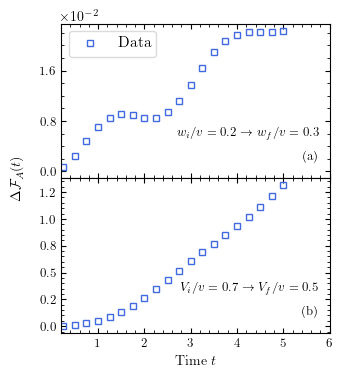

In [33]:
figure_SSH_paper()